# DP4 – Imputation with linear regression using other variables

**Idea:** predict a missing value from *other variables* that are strongly correlated with it, using a linear regression.

**Problem:** our file only contains PM10 of Lehen (no other stations or weather data).
**Solution:** we build the "other variables" from the time series itself by shifting it in time:
- `prev`  = value 30 min **before**   (t − 1)
- `next`  = value 30 min **after**    (t + 1)
- `prev2` = value 1 h before (t − 2), `next2` = value 1 h after (t + 2)
- `day_before` = value 24 h before (t − 48), `day_after` = value 24 h after (t + 48)

These are known even when the value at time t is missing (missing values are never next to each other).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = pd.read_csv("../ex22PM10imputation.csv", sep=";", header=None, names=["pm10_missing", "pm10_true"])
s = df["pm10_missing"]
missing = s.isna()

X = pd.DataFrame({
    "prev":       s.shift(1),
    "next":       s.shift(-1),
    "prev2":      s.shift(2),
    "next2":      s.shift(-2),
    "day_before": s.shift(48),
    "day_after":  s.shift(-48),
})
X["pm10"] = s
print(X.head(3))

    prev   next  prev2  next2  day_before  day_after   pm10
0    NaN  336.1    NaN  242.7         NaN       31.4  642.2
1  642.2  242.7    NaN  201.1         NaN       32.2  336.1
2  336.1  201.1  642.2  165.7         NaN       32.3  242.7


## (a) Which variables are highly correlated with PM10?
`corr()` computes the Pearson correlation (−1 … +1). Values close to 1 = strong linear relationship.

prev          0.947
next          0.947
prev2         0.922
next2         0.922
day_before    0.562
day_after     0.562
Name: pm10, dtype: float64


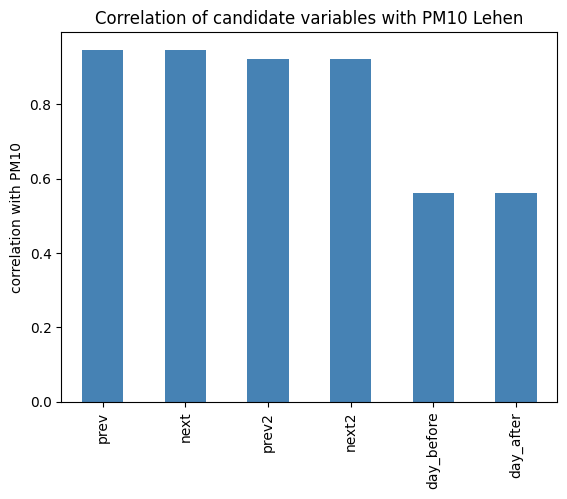

In [2]:
corr = X.corr()["pm10"].drop("pm10").sort_values(ascending=False)
print(corr.round(3))

corr.plot(kind="bar", color="steelblue")
plt.ylabel("correlation with PM10")
plt.title("Correlation of candidate variables with PM10 Lehen")
plt.show()

➡ `prev` and `next` have the highest correlation (≈ 0.95), `day_before`/`day_after` are much weaker.
We choose **`prev` and `next`** as input variables.

## (b) Linear regression imputation
1. Train the model on all rows where PM10 **and** both inputs are known.
2. Predict PM10 for the 300 missing rows.

The model is:  `PM10(t) = b0 + b1 · prev + b2 · next`

In [3]:
features = ["prev", "next"]

train = X[~missing].dropna()                     # rows where everything is known
model = LinearRegression()
model.fit(train[features], train["pm10"])
print("Intercept b0:", round(model.intercept_, 3))
print("Coefficients:", dict(zip(features, model.coef_.round(3))))

X_missing = X.loc[missing, features]
imp_reg = s.copy()
imp_reg[missing] = model.predict(X_missing)

Intercept b0: 0.141
Coefficients: {'prev': np.float64(0.428), 'next': np.float64(0.564)}


➡ The coefficients are ≈ 0.43 and 0.56 (sum ≈ 1) – the regression basically **learned a (weighted) linear interpolation by itself**.

## (c) Compare with the last-value method
We plot the imputed values against the true values (**scatter plot**): the closer to the diagonal, the better.
We also show both error distributions as boxplots.

MAE regression : 1.42
MAE last value : 2.11


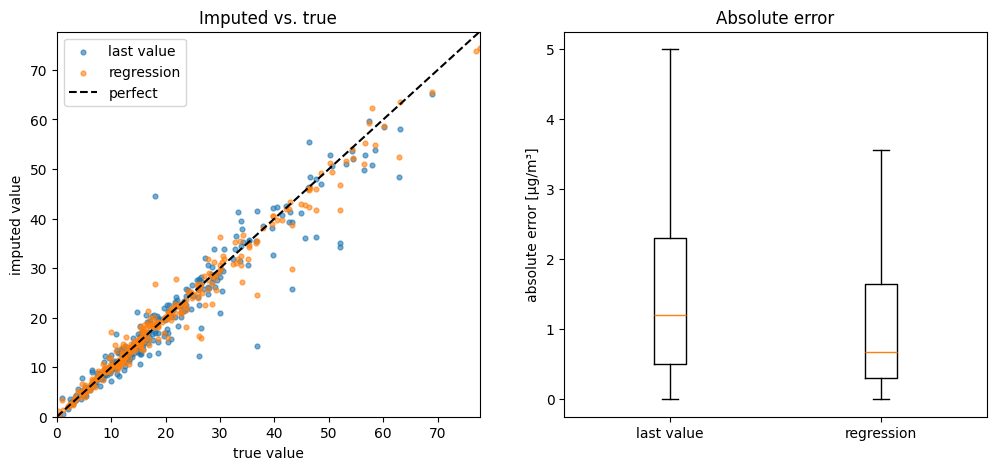

In [4]:
imp_last = s.ffill()
true = df["pm10_true"][missing]

err_reg  = (imp_reg[missing]  - true).abs()
err_last = (imp_last[missing] - true).abs()
print("MAE regression :", round(err_reg.mean(), 2))
print("MAE last value :", round(err_last.mean(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(true, imp_last[missing], s=12, alpha=0.6, label="last value")
ax[0].scatter(true, imp_reg[missing],  s=12, alpha=0.6, label="regression")
lim = [0, true.quantile(0.99)]
ax[0].plot(lim, lim, "k--", label="perfect")
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("true value"); ax[0].set_ylabel("imputed value")
ax[0].set_title("Imputed vs. true"); ax[0].legend()

ax[1].boxplot([err_last, err_reg], showfliers=False)
ax[1].set_xticks([1, 2], ["last value", "regression"])
ax[1].set_ylabel("absolute error [µg/m³]")
ax[1].set_title("Absolute error")
plt.show()

## Summary
- The best "other variables" are the neighbours in time (`prev`, `next`, correlation ≈ 0.95).
- The regression model `PM10 ≈ 0.14 + 0.43·prev + 0.56·next` gives a **clearly smaller error than the last-value method** (MAE 1.42 vs. 2.11).
- It is almost identical to linear interpolation (MAE 1.36) – which explains why interpolation won in DP3.
- With real extra variables (e.g. PM10 of a neighbouring station, wind, temperature) the same code works: just put these columns into `X`.